# Heart Disease Prediction using Machine Learning

## Problem Statement

The objective of this project is to predict whether a patient has heart disease using machine learning algorithms based on clinical and medical attributes.

This project is part of the DataMites AI Internship Capstone Program.

Data Pipeline Overview:-
------------------------
1. Problem Statement   
2. Import Required Libraries
3. Load the Dataset
4. Data Understanding
5. Data Cleaning
6. Exploratory Data Analysis (EDA)
7. Feature Engineering
8. Feature Scaling
9. Train-Test Split
10. Model Building
    * Logistic Regression
    * Decision Tree
    * Random Forest
    * KNN
    * SVM
    * XGBoost
11. Model Evaluation
12. Model Comparison
13. Best Model Selection
14. Conclusion

#### IMPORT LIBRARIES

In [1]:
# Data Handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
!pip install xgboost

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Advanced Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Boosting
from xgboost import XGBClassifier

# Metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [2]:
values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")

In [3]:
values.head(5)

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [4]:
labels.head(5)

,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [5]:
df = pd.merge(values,labels, on = "patient_id")       

Why we are using "merge" here ?

As we seen the Dataset we have "values.csv" with on "Input Feature" columns, But not the "Target column".              
As for the "Target column" we have it in the "labels.csv"        

So, we are merging on "patient_id", you create one complete dataset ready for "EDA" and modeling.

In [6]:
df

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0


In [7]:
df.head(5)

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [8]:
df.tail(5)

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
175,5qfar3,2,reversible_defect,125,4,2,1,0,254,0.2,1,67,163,0,1
176,2s2b1f,2,normal,180,4,0,0,1,327,3.4,0,55,117,1,1
177,nsd00i,2,reversible_defect,125,3,0,0,0,309,1.8,1,64,131,1,1
178,0xw93k,1,normal,124,3,2,1,0,255,0.0,1,48,175,0,0
179,2nx10r,1,normal,160,3,1,0,0,201,0.0,0,54,163,0,0


In [9]:
df.shape

(180, 15)

In [10]:
df.columns

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina',
       'heart_disease_present'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [12]:
df.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667,0.444444
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474,0.498290
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000,1.000000


In [13]:
df.isna().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

In [14]:
df.isna().sum().sum()

np.int64(0)

In [15]:
df.duplicated().sum()

np.int64(0)

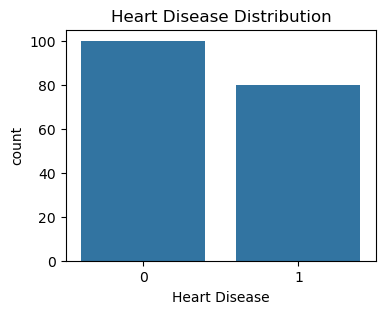

In [16]:
plt.figure(figsize=(4,3))
sns.countplot(df,x = "heart_disease_present")
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("count")
plt.show()

As we cann see the chart that "Dataset is Well_Balanced", with approximately 100 patients not having heart disease and 80 patients having heart disease. Therefore, no class balancing techniques (Like SMOTE or undersampling) are required before model training.

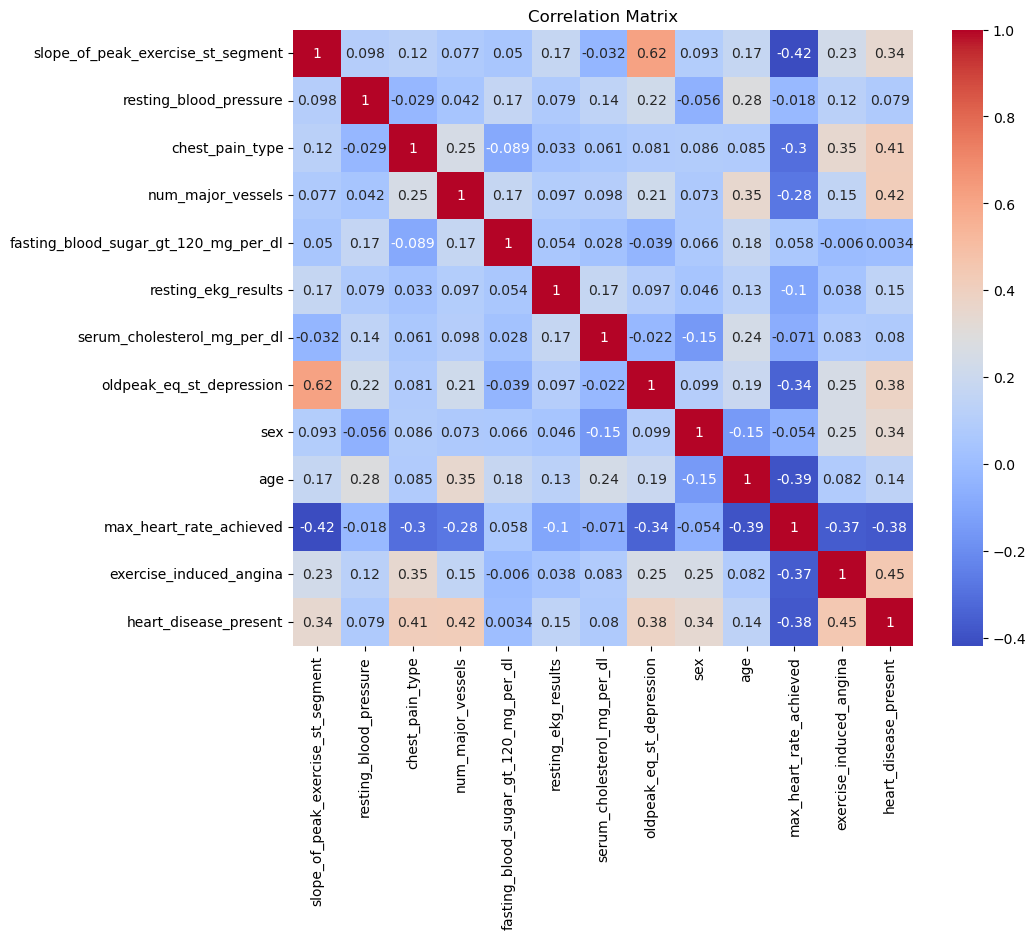

In [17]:
plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")

plt.show()

We us correlation matrix here to show how different features are related to each other and to the "target variable or heart_disease_present          


As we observe the heat map, We have some "NEGATIVE and POSITIVE even ZERO's". These will is their any relation between them.

Positive values : Postive Values tell as one Feature Increases, the chance of "Heart Disease also Increases".      

Negative values : Like As one feature increases, the chance of "Heart Disease also Decreases".           

Zero's : As for the Zero's, It may have "Little Relation" or may not have any "Relation"

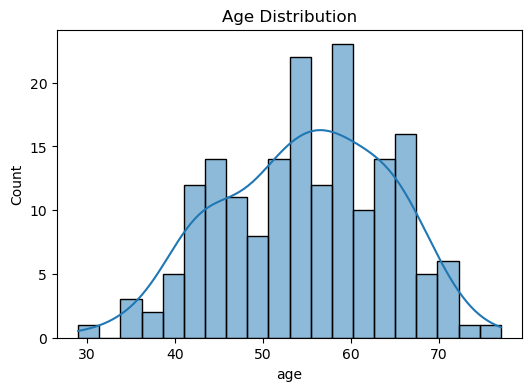

In [18]:
plt.figure(figsize=(6,4))

sns.histplot(df['age'], bins=20, kde=True)

plt.title("Age Distribution")

plt.show()

Here We are checking weather the Person(He/She) will like to be affect the Heart Disease.       

You can see that "The people who most affectly by the Heart Disease are between 45 to 65".

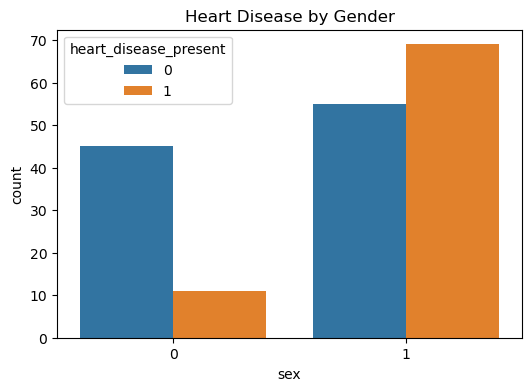

In [19]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='sex',
    hue='heart_disease_present',
    data=df
)

plt.title("Heart Disease by Gender")

plt.show()

From the chart, we can observe that female patients (0) have fewer cases of heart disease, while male patients (1) have a higher number of heart disease cases.                                           

This indicates that male patients are more likely to be affected by heart disease in the data we have.

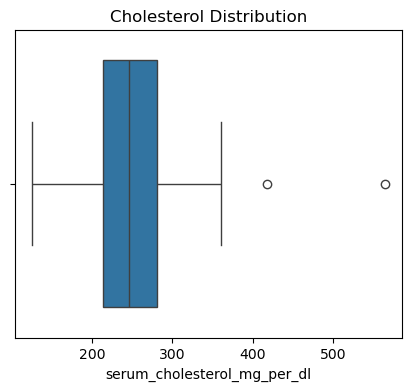

In [20]:
plt.figure(figsize=(5,4))

sns.boxplot(x=df['serum_cholesterol_mg_per_dl'])

plt.title("Cholesterol Distribution")

plt.show()

The box plot shows that most patients have serum cholesterol levels between 210 and 280 mg/dL, with a median of approximately 250 mg/dL.   

A few patients have unusually high cholesterol levels, which appear as outliers.                      

These outliers may require further investigation during data preprocessing.

In [21]:
df.dtypes

patient_id                               object
slope_of_peak_exercise_st_segment         int64
thal                                     object
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
heart_disease_present                     int64
dtype: object

From the Data we have, We can see that we two Object Types columns    
1.patient_id                  
2.thal    

We will leave the "patient_id", because due it's unique numbers.                
As for "thal", We will check it's value counts, To check how many different types of values it have 

In [22]:
df['thal'].value_counts()

thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64

As we can see, we have three types of unique values in 'thal', So, we are using get_dummies for this

In [23]:
df = pd.get_dummies(data=df,
                    columns=["thal"],
                    drop_first=True,
                    dtype=int
)

In [24]:
df.head()

,patient_id,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,thal_normal,thal_reversible_defect
0,0z64un,1,128,2,0,0,2,308,0.0,1,45,170,0,0,1,0
1,ryoo3j,2,110,3,0,0,0,214,1.6,0,54,158,0,0,1,0
2,yt1s1x,1,125,4,3,0,2,304,0.0,1,77,162,1,1,1,0
3,l2xjde,1,152,4,0,0,0,223,0.0,1,40,181,0,1,0,1
4,oyt4ek,3,178,1,0,0,2,270,4.2,1,59,145,0,0,0,1


And we are removing or drop the column "patient_id".

In [25]:
df.drop('patient_id', axis=1, inplace=True)

In [26]:
df.head()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present,thal_normal,thal_reversible_defect
0,1,128,2,0,0,2,308,0.0,1,45,170,0,0,1,0
1,2,110,3,0,0,0,214,1.6,0,54,158,0,0,1,0
2,1,125,4,3,0,2,304,0.0,1,77,162,1,1,1,0
3,1,152,4,0,0,0,223,0.0,1,40,181,0,1,0,1
4,3,178,1,0,0,2,270,4.2,1,59,145,0,0,0,1


In [27]:
X = df.drop("heart_disease_present",axis = 1)     #Input features
y = df["heart_disease_present"]

In [28]:
X

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,thal_normal,thal_reversible_defect
0,1,128,2,0,0,2,308,0.0,1,45,170,0,1,0
1,2,110,3,0,0,0,214,1.6,0,54,158,0,1,0
2,1,125,4,3,0,2,304,0.0,1,77,162,1,1,0
3,1,152,4,0,0,0,223,0.0,1,40,181,0,0,1
4,3,178,1,0,0,2,270,4.2,1,59,145,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,2,125,4,2,1,0,254,0.2,1,67,163,0,0,1
176,2,180,4,0,0,1,327,3.4,0,55,117,1,1,0
177,2,125,3,0,0,0,309,1.8,1,64,131,1,0,1
178,1,124,3,2,1,0,255,0.0,1,48,175,0,1,0


In [29]:
y

0      0
1      0
2      1
3      1
4      0
      ..
175    1
176    1
177    1
178    0
179    0
Name: heart_disease_present, Length: 180, dtype: int64

In [30]:
# Train_Test_Split

In [31]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(144, 14)
(36, 14)
(144,)
(36,)


In [33]:
# Scaling

In [34]:
scaler = StandardScaler()

XT_train = scaler.fit_transform(X_train)
XT_test = scaler.transform(X_test)

In [35]:
print(XT_train)

[[-0.83240511 -1.26167976  0.88114311 ... -0.69608626 -1.10244484
   1.21768576]
 [-0.83240511 -0.32154064  0.88114311 ...  1.43660356 -1.10244484
   1.21768576]
 [ 0.74478352 -0.96788628  0.88114311 ... -0.69608626  0.90707486
  -0.82122993]
 ...
 [ 0.74478352 -0.67409281 -2.31762852 ...  1.43660356 -1.10244484
   1.21768576]
 [-0.83240511  0.20728762 -0.1851141  ... -0.69608626  0.90707486
  -0.82122993]
 [ 0.74478352 -1.26167976  0.88114311 ...  1.43660356 -1.10244484
   1.21768576]]


In [36]:
print(XT_test)

[[-8.32405113e-01  2.66046314e-01 -1.25137131e+00  1.34067008e+00
   2.23606798e+00  9.96545926e-01  1.54523484e+00 -8.68274885e-01
  -1.43660356e+00  3.32002872e-01  1.04728464e-01 -6.96086261e-01
   9.07074865e-01 -8.21229934e-01]
 [-8.32405113e-01 -1.26167976e+00 -1.85114099e-01  3.13773848e-01
   2.23606798e+00  9.96545926e-01  3.95732677e-01 -8.68274885e-01
  -1.43660356e+00  1.78074268e+00 -8.94608202e-01 -6.96086261e-01
   9.07074865e-01 -8.21229934e-01]
 [-8.32405113e-01 -1.14416237e+00  8.81143110e-01  3.13773848e-01
  -4.47213595e-01  9.96545926e-01  9.27909606e-01 -8.68274885e-01
   6.96086261e-01 -1.22817846e+00  1.50152858e-01 -6.96086261e-01
   9.07074865e-01 -8.21229934e-01]
 [ 7.44783522e-01  7.94874569e-01  8.81143110e-01  1.34067008e+00
  -4.47213595e-01  9.96545926e-01  7.57612989e-01  1.66309484e+00
   6.96086261e-01  5.54885918e-01 -3.49515475e-01  1.43660356e+00
  -1.10244484e+00  1.21768576e+00]
 [-8.32405113e-01  5.01081094e-01 -1.25137131e+00  1.34067008e+00
  

In [37]:
lr = LogisticRegression(random_state=42)

lr.fit(XT_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [38]:
y_pred_lr = lr.predict(XT_test)

In [39]:
# Accuracy

In [40]:
accuracy = accuracy_score(y_test,y_pred_lr)

print("Accuracy:", accuracy)

Accuracy: 0.8333333333333334


In [41]:
cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion matrix : ")
print(cm)

Confusion matrix : 
[[15  1]
 [ 5 15]]


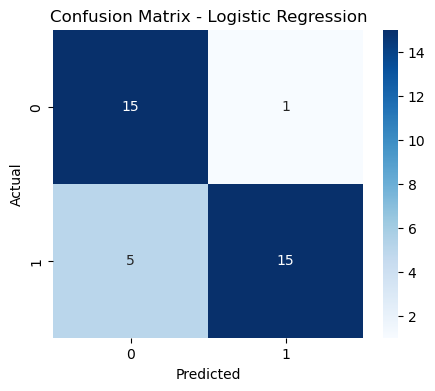

In [42]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

The confusion matrix shows that the "Logistic Regression" model correctly classified 15 patients without heart disease and 15 patients with heart disease. It made "1 false positive (FP) prediction" and "5 false negative (FN) predictions". Overall, the model performs well, but reducing false negatives is important because missing patients with heart disease could delay diagnosis and treatment.

In [43]:
Cr = classification_report(y_test, y_pred_lr)
print("classification_report : ")
print(Cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



From the Classification Report we got, We can notice we have some things

Accuracy = 83%  
--------------
We can say that the Logistic Regression model correctly predicted 83% of the patients in the test dataset.        

Precision = 0.94(94%) for CLASS 1 
---------------------------------
The model predicts that a patient has heart disease, it is correct 94% of the time.

Recall = 0.75(75%) for  CLASS 1          
-------------------------------
The model correctly identified 75% of the patients who actually have heart disease, but missed the remaining 25%.    

F1-Score = 0.83(83%)          
--------------------
The F1-score combines Precision and Recall into a single metric.           
This indicates a good balance between correctly identifying heart disease and avoiding false alarms.            



So,Final Overview :         
--------------------
The Logistic Regression model achieved an accuracy of 83% on the test dataset. It showed a high precision of 94% for predicting heart disease, meaning most positive predictions were correct. However, the recall for heart disease was 75%, indicating that the model missed some patients who actually had the disease. Overall, the model provides a good balance between precision and recall, with an F1-score of 83%.

Is Logistic Regression is good model, We don't know. For this we have check check the other models (Like, Random_Forest, Decision_Tree, SVM, etc)

Decision_Tree
-------------

In [44]:
tree = DecisionTreeClassifier(random_state=42)

tree.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [45]:
D_pred = tree.predict(X_test)

In [46]:
D_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0])

In [47]:
D_accuracy = accuracy_score(y_test, D_pred)

print("Decision Tree Accuracy:", D_accuracy)

Decision Tree Accuracy: 0.8055555555555556


In [48]:
cm = confusion_matrix(y_test, D_pred)
print("Confusion matrix : ")
print(cm)

Confusion matrix : 
[[15  1]
 [ 6 14]]


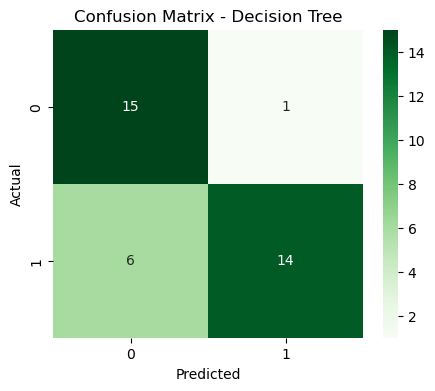

In [49]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")

plt.show()

The Decision Tree model correctly classified 15 healthy patients and 14 patients with heart disease. It made 1 false positive prediction and 6 false negative predictions. The model achieved an overall accuracy of 80.56%.

In [50]:
Cr = classification_report(y_test, D_pred)
print("classification_report : ")
print(Cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.71      0.94      0.81        16
           1       0.93      0.70      0.80        20

    accuracy                           0.81        36
   macro avg       0.82      0.82      0.81        36
weighted avg       0.84      0.81      0.80        36



From the Classification Report we got, We can notice we have some things

Accuracy = 80.56%  
--------------
We can say that the Decision Tree correctly predicted 80.5% of the patients in the test dataset.        

Precision = 0.93(93%) for CLASS 1 
---------------------------------
The model predicts that a patient has heart disease, it is correct 93% of the time.

Recall = 0.70(70%) for  CLASS 1          
-------------------------------
The model correctly identified 70% of the patients who actually have heart disease, but missed the remaining 30%.    

F1-Score = 0.80(80%)          
--------------------
The F1-score combines Precision and Recall into a single metric.           
This indicates a good balance between correctly identifying heart disease and avoiding false alarms.            



So,Final Overview :         
--------------------
The Decision Tree model achieved an accuracy of 80.56%. It showed high precision (93%) for predicting heart disease, meaning most positive predictions were correct. However, the recall was 70%, indicating that the model missed some patients who actually had heart disease. Overall, the model performed reasonably well but was slightly less effective than Logistic Regression..

Conclusion
----------
Logistic Regression is performing better than Decision Tree because it has: 

Higher accuracy                          
Better recall for heart disease patients                       
Better F1-score                               

For medical prediction, Recall is especially important because we want to minimize the number of patients with heart disease who are incorrectly classified as healthy.

### Random_Forest

In [51]:
from sklearn.ensemble import RandomForestClassifier

R_model = RandomForestClassifier(n_estimators=100,random_state=42)
R_model.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [52]:
R_pred = R_model.predict(X_test)

In [53]:
R_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

In [54]:
R_accuracy = accuracy_score(y_test, R_pred)

print("Random Forest Accuracy:", R_accuracy)

Random Forest Accuracy: 0.8611111111111112


In [55]:
cm = confusion_matrix(y_test, R_pred)
print("Confusion matrix : ")
print(cm)

Confusion matrix : 
[[16  0]
 [ 5 15]]


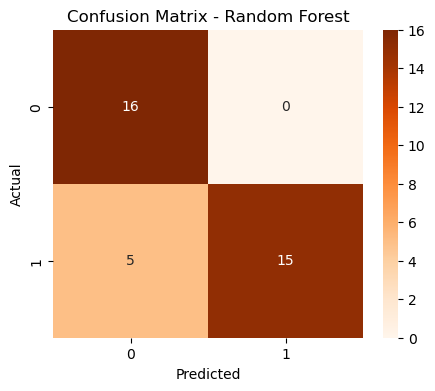

In [56]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Oranges'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")

plt.show()

In [57]:
Cr = classification_report(y_test, R_pred)
print("classification_report : ")
print(Cr)

classification_report : 
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        16
           1       1.00      0.75      0.86        20

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36



Random Forest Observation:
--------------------------

Accuracy = 86.11%
------------------

The Random Forest model correctly predicted 86.11% of the patients in the test dataset.

Precision = 1.00 (100%) for CLASS 1
-----------------------------------

When the model predicts that a patient has heart disease, it is 100% correct.

Recall = 0.75 (75%) for CLASS 1
-------------------------------

The model correctly identified 75% of the patients who actually have heart disease but missed the remaining 25%.

F1-Score = 0.86 (86%)
----------------------

The F1-score indicates a good balance between Precision and Recall.

Final Overview:
---------------

The Random Forest model achieved an accuracy of 86.11%, which is the highest among the models, We have evaluated so far. It achieved 100% precision for heart disease prediction, meaning every positive prediction was correct. The model also maintained a good F1-score of 86%, making it one of the best-performing models for this dataset.

### KNN

In [58]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(XT_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [59]:
K_pred = knn.predict(XT_test)
K_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0])

In [60]:
K_accuracy = accuracy_score(y_test, K_pred)
print("KNN Accuracy : ",K_accuracy)

KNN Accuracy :  0.8333333333333334


In [61]:
cm = confusion_matrix(y_test, K_pred)

print(cm)

[[15  1]
 [ 5 15]]


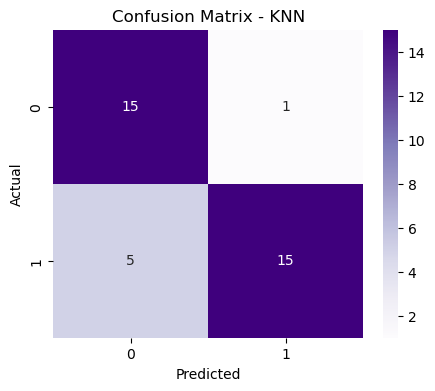

In [62]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Purples'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")

plt.show()

In [63]:
Cr = classification_report(y_test, K_pred)

print("Classification Report:")
print(Cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



K-Nearest Neighbors (KNN) Observation:
--------------------------------------

Accuracy = 83.33%
-----------------

The KNN model correctly predicted 83.33% of the patients in the test dataset.

Precision = 0.94 (94%) for CLASS 1
-----------------------------------

When the model predicts that a patient has heart disease, it is 94% correct.

Recall = 0.75 (75%) for CLASS 1
-------------------------------

The model correctly identified 75% of the patients who actually have heart disease.

F1-Score = 0.83 (83%)
---------------------

The F1-score indicates a good balance between Precision and Recall.

Final Overview"
--------------

The KNN model achieved an accuracy of 83.33%. It performed similarly to Logistic Regression, providing good precision and recall while maintaining an F1-score of 83%. Overall, it is a reliable model for heart disease prediction.

### SVM

In [64]:
svm = SVC(kernel='rbf', random_state=42)
svm.fit(XT_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [65]:
S_pred = svm.predict(XT_test)
S_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

In [66]:
S_accuracy = accuracy_score(y_test, S_pred)

print("SVM Accuracy: ",S_accuracy)

SVM Accuracy:  0.8611111111111112


In [67]:
cm = confusion_matrix(y_test, S_pred)

print(cm)

[[16  0]
 [ 5 15]]


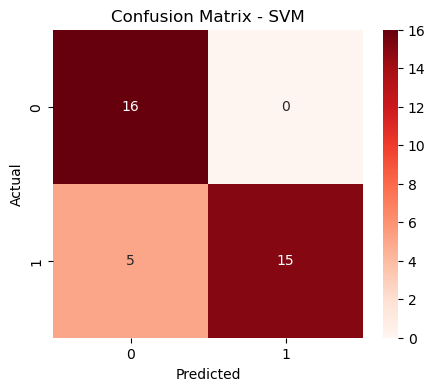

In [68]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

In [69]:
Cr = classification_report(y_test, S_pred)

print("Classification Report:")
print(Cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86        16
           1       1.00      0.75      0.86        20

    accuracy                           0.86        36
   macro avg       0.88      0.88      0.86        36
weighted avg       0.89      0.86      0.86        36



Support Vector Machine (SVM) Observation:
-----------------------------------------

Accuracy = 86.11%
-----------------

The SVM model correctly predicted 86.11% of the patients in the test dataset.

Precision = 1.00 (100%) for CLASS 1
-----------------------------------

When the model predicts heart disease, it is 100% correct.

Recall = 0.75 (75%) for CLASS 1
-------------------------------

The model correctly identified 75% of the patients who actually have heart disease.

F1-Score = 0.86 (86%)
---------------------

The F1-score shows a strong balance between Precision and Recall.

Final Overview
--------------

The Support Vector Machine (SVM) model achieved an accuracy of 86.11%. It showed excellent precision and good recall, making it one of the best-performing models in this project. Its performance was comparable to the Random Forest model.

### XGBoost

In [70]:
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [71]:
X_pred = xgb.predict(X_test)
X_pred

array([0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0])

In [72]:
X_accuracy = accuracy_score(y_test, X_pred)

print("XGBoost Accuracy:",X_accuracy)

XGBoost Accuracy: 0.8333333333333334


In [73]:
cm = confusion_matrix(y_test, X_pred)

print(cm)

[[15  1]
 [ 5 15]]


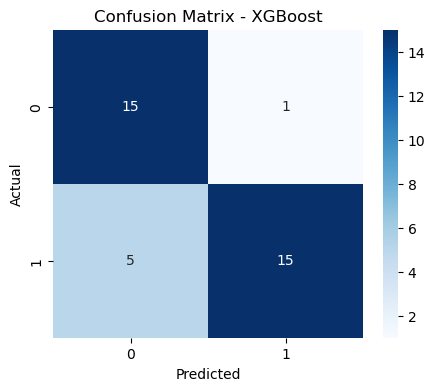

In [74]:
plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - XGBoost")

plt.show()

In [75]:
Cr = classification_report(y_test, X_pred)

print("Classification Report:")
print(Cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.94      0.83        16
           1       0.94      0.75      0.83        20

    accuracy                           0.83        36
   macro avg       0.84      0.84      0.83        36
weighted avg       0.85      0.83      0.83        36



XGBoost Observation:
--------------------

Accuracy = 83.33%
-----------------

The XGBoost model correctly predicted 83.33% of the patients in the test dataset.

Precision = 0.94 (94%) for CLASS 1
----------------------------------

When the model predicts heart disease, it is 94% correct.

Recall = 0.75 (75%) for CLASS 1
-------------------------------

The model correctly identified 75% of the patients who actually have heart disease.

F1-Score = 0.83 (83%)
---------------------

The F1-score indicates good overall performance.

Final Overview
--------------

The XGBoost model achieved an accuracy of 83.33%. It demonstrated good precision, recall, and F1-score, making it a reliable model for predicting heart disease. However, its performance was slightly lower than Random Forest and SVM on this dataset.

In [76]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "XGBoost"
    ],
    "Accuracy (%)": [
        83.33,
        80.56,
        86.11,
        83.33,
        86.11,
        83.33
    ]
})

comparison.sort_values(
    by="Accuracy (%)",
    ascending=False,
    inplace=True
)

comparison

,Model,Accuracy (%)
2,Random Forest,86.11
4,SVM,86.11
0,Logistic Regression,83.33
3,KNN,83.33
5,XGBoost,83.33
1,Decision Tree,80.56


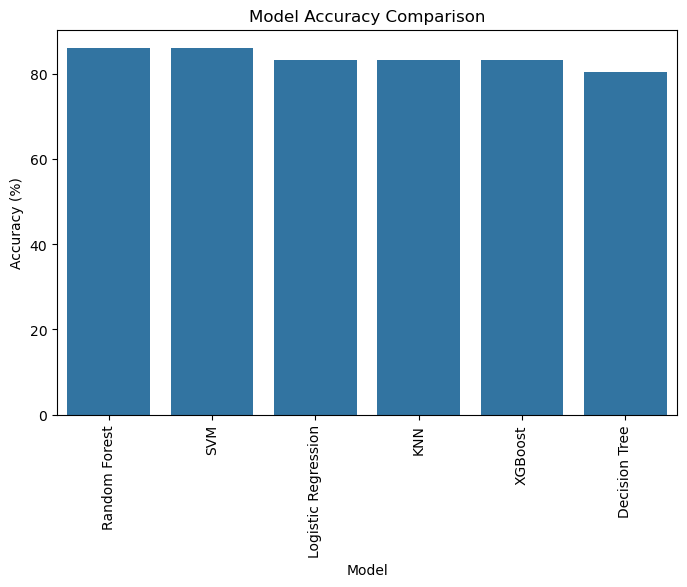

In [77]:
plt.figure(figsize=(8,5))

sns.barplot(
    x="Model",
    y="Accuracy (%)",
    data=comparison
)

plt.title("Model Accuracy Comparison")
plt.xticks(rotation=90)

plt.show()

Conclusion:
-----------
Six machine learning models were trained and evaluated for heart disease prediction. 

Logistic Regression -------------- 83.33 % 

Decision Tree  ------------------- 80.56 %

Random Forest  ------------------- 86.11 %

KNN ------------------------------ 83.33 %

SVM ------------------------------ 86.11 %

XGBoost -------------------------- 83.33 %

Among all the models, Random Forest and Support Vector Machine (SVM) achieved the highest accuracy of 86.11%.

Although both models performed equally well, Random Forest is selected as the final model because it:

works effectively on structured tabular data,           
handles outliers well,         
does not require feature scaling,           
provides feature importance, making the predictions easier to interpret.             

Therefore, Random Forest is chosen as the final model for heart disease prediction.

Challenges:-
------------
1. Merging multiple datasets correctly.
2. Understanding medical features.
3. Encoding categorical variables.
4. Applying feature scaling only where required.
5. Comparing multiple machine learning models.
6. Selecting the best model based on multiple evaluation metrics.
7. Interpreting model performance for a healthcare application.